# 01 EDA (train split only)

This notebook looks only at `splits/train.csv`. Val and test are not opened here, so nothing we learn
about the data can leak into decisions that are later checked on val or test.

Each plot ends with two short notes: **What we learn** and **Impact on next steps**.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import config as C

FIG_DIR = ROOT / "docs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv(C.SPLITS_DIR / "train.csv")
df["year"] = df.class_name.str[-4:].astype(int)
df["bw"] = df.x2 - df.x1
df["bh"] = df.y2 - df.y1
df["area_ratio"] = df.bw * df.bh / (df.width * df.height)
print(len(df), "train images,", df.label.nunique(), "classes,", df.make.nunique(), "makes")

6922 train images, 196 classes, 49 makes


## 1. Images per class

min 20, median 36, max 58, max/min ratio 2.9


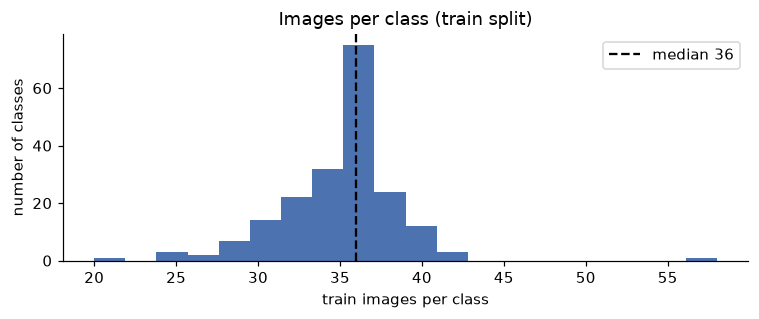

In [2]:
counts = df.label.value_counts()
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(counts, bins=20, color="#4c72b0")
ax.axvline(counts.median(), color="k", ls="--", label=f"median {counts.median():.0f}")
ax.set(xlabel="train images per class", ylabel="number of classes", title="Images per class (train split)")
ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "eda_images_per_class.png")
print(f"min {counts.min()}, median {counts.median():.0f}, max {counts.max()}, max/min ratio {counts.max()/counts.min():.1f}")

**What we learn:** every class has 20 to 58 training images (median 36). The imbalance is mild, under 3x,
but the absolute numbers are tiny for 196 fine-grained classes.

**Impact on next steps:** no class weighting or resampling is needed. With so few images per class,
training from scratch is hopeless, so we start from ImageNet weights, and we use augmentation and early
stopping to fight overfitting. Plain top-1 accuracy is a fair headline metric because classes are balanced.

## 2. Classes per make

{'Chevrolet': 22, 'Dodge': 15, 'Audi': 14, 'BMW': 13, 'Ford': 12, 'Hyundai': 11, 'Acura': 6, 'Bentley': 6}
makes with a single class: 19


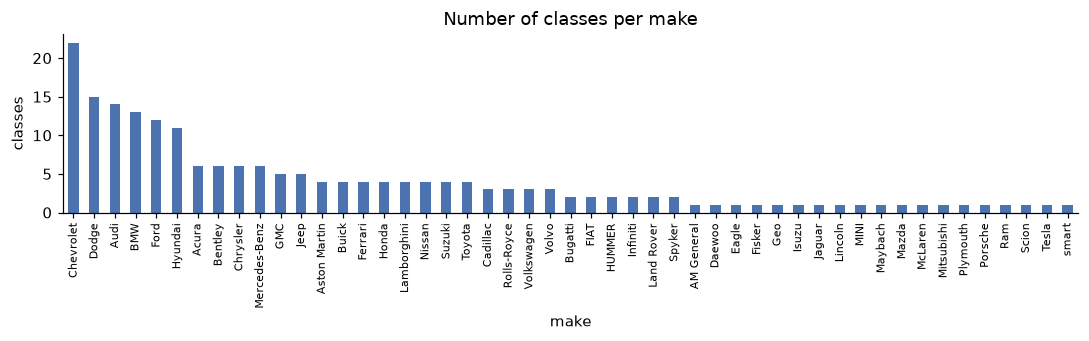

In [3]:
per_make = df.drop_duplicates("label").make.value_counts()
fig, ax = plt.subplots(figsize=(10, 3.2))
per_make.plot.bar(ax=ax, color="#4c72b0")
ax.set(ylabel="classes", title="Number of classes per make")
ax.tick_params(axis="x", labelsize=7)
fig.tight_layout(); fig.savefig(FIG_DIR / "eda_classes_per_make.png")
print(per_make.head(8).to_dict())
print("makes with a single class:", (per_make == 1).sum())

**What we learn:** six makes (Chevrolet 22, Dodge 15, Audi 14, BMW 13, Ford 12, Hyundai 11) hold 87 of the
196 classes. Inside a make, cars share the grille, badge, and design language, so those classes differ in
small details. 19 makes have only one class, so for them "right make" already means "right class".

**Impact on next steps:** in the error analysis we split mistakes into within-make and cross-make. We expect
most errors to be within-make, and those few big makes are where we will look first.

## 3. Model year distribution

{1991: 1, 1993: 3, 1994: 3, 1997: 1, 1998: 2, 1999: 1, 2000: 1, 2001: 2, 2002: 1, 2006: 1, 2007: 25, 2008: 7, 2009: 13, 2010: 10, 2011: 8, 2012: 117}

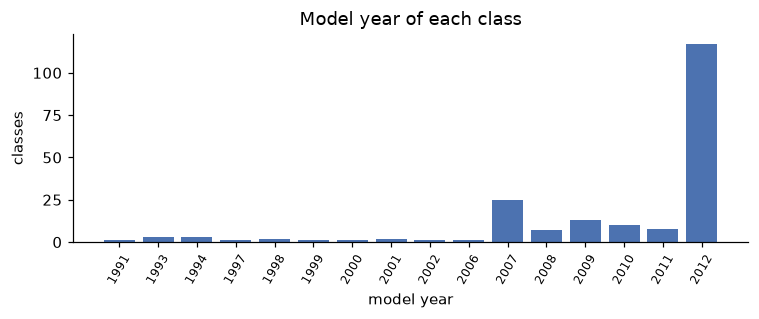

In [4]:
years = df.drop_duplicates("label").year.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(years.index.astype(str), years.values, color="#4c72b0")
ax.set(xlabel="model year", ylabel="classes", title="Model year of each class")
ax.tick_params(axis="x", rotation=60, labelsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / "eda_years.png")
print(years.to_dict())

**What we learn:** 117 of 196 classes are 2012 models and almost nothing is newer. Some classes differ only
by year (Audi S4 Sedan 2007 vs 2012, Dodge Caliber Wagon 2007 vs 2012, Dodge Durango 2007 vs 2012).

**Impact on next steps:** a car on a real street today is very likely a model this dataset has never seen.
The classifier must be able to say "not sure" instead of forcing one of 196 labels, which is why the
confidence threshold study (analysis 7b) is part of the plan. Year-only pairs are good candidates for the
confusion gallery.

## 4. Image size

         count   mean    std   min    25%    50%    75%     max
width   6922.0  701.0  449.0  78.0  429.0  640.0  800.0  4608.0
height  6922.0  483.0  317.0  57.0  290.0  424.0  540.0  3456.0
shorter side < 224px: 0.169


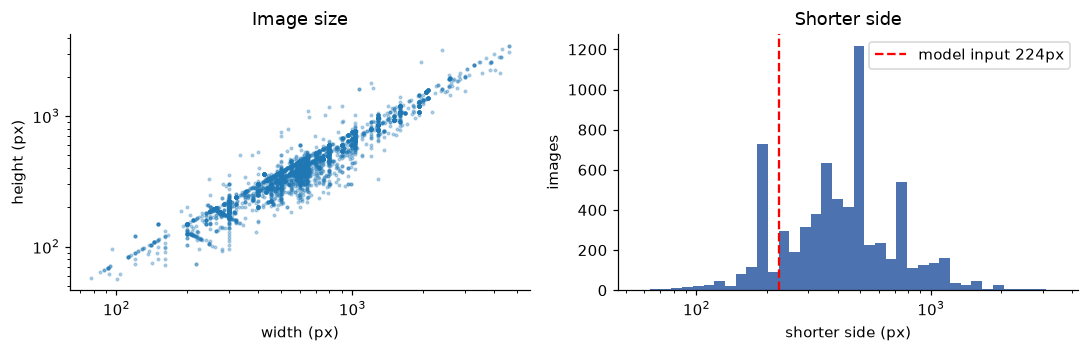

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
axes[0].scatter(df.width, df.height, s=3, alpha=0.3)
axes[0].set(xscale="log", yscale="log", xlabel="width (px)", ylabel="height (px)", title="Image size")
short = np.minimum(df.width, df.height)
axes[1].hist(short, bins=np.logspace(np.log10(short.min()), np.log10(short.max()), 40), color="#4c72b0")
axes[1].axvline(C.IMG_SIZE, color="r", ls="--", label=f"model input {C.IMG_SIZE}px")
axes[1].set(xscale="log", xlabel="shorter side (px)", ylabel="images", title="Shorter side")
axes[1].legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "eda_image_size.png")
print(df[["width", "height"]].describe().round(0).T)
print("shorter side < 224px:", (short < 224).mean().round(3))

**What we learn:** sizes vary a lot (78 px to 4608 px wide, median 640 x 424). Most images are larger than the
224 px model input, but about 17% have a shorter side under 224 px and get upscaled.

**Impact on next steps:** we resize everything to a fixed 224 x 224. Because a part of the data is already
low resolution, the model sees some natural blur, but not the extreme 32 to 64 px case. The degradation
experiment (7c) tests that range on purpose.

## 5. Bounding box size and shape

box w/h median 1.87  IQR [1.59, 2.25]


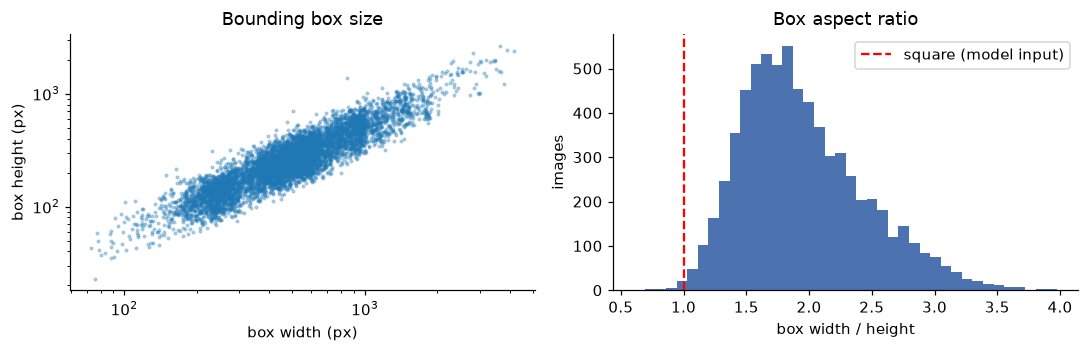

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
axes[0].scatter(df.bw, df.bh, s=3, alpha=0.3)
axes[0].set(xscale="log", yscale="log", xlabel="box width (px)", ylabel="box height (px)", title="Bounding box size")
aspect = df.bw / df.bh
axes[1].hist(aspect, bins=40, color="#4c72b0")
axes[1].axvline(1, color="r", ls="--", label="square (model input)")
axes[1].set(xlabel="box width / height", ylabel="images", title="Box aspect ratio")
axes[1].legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "eda_bbox_size.png")
print("box w/h median", aspect.median().round(2), " IQR", aspect.quantile([.25, .75]).round(2).tolist())

**What we learn:** cars are wide. The median box is about 1.9 times wider than tall, and almost no box is
square.

**Impact on next steps:** the usual ImageNet recipe (resize the short side to 256, then center crop 224)
would cut off the front and back of a wide car, and headlights, taillights, and grilles are exactly the
details that separate similar models. So we resize the whole crop to 224 x 224 directly (a slight squash)
instead of center cropping. The squash is the same for every image, so the model can learn it.

## 6. How much of the image is the car?

{'count': 6922.0, 'mean': 0.545, 'std': 0.17, 'min': 0.042, '25%': 0.423, '50%': 0.542, '75%': 0.664, 'max': 0.995}
share of images where the car covers < 30% of the frame: 0.074


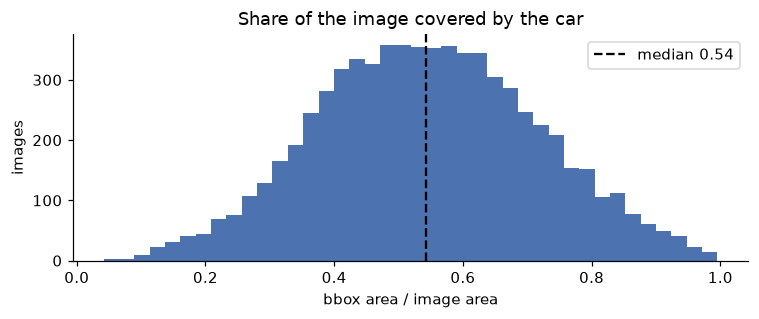

In [7]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(df.area_ratio, bins=40, color="#4c72b0")
ax.axvline(df.area_ratio.median(), color="k", ls="--", label=f"median {df.area_ratio.median():.2f}")
ax.set(xlabel="bbox area / image area", ylabel="images", title="Share of the image covered by the car")
ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "eda_area_ratio.png")
print(df.area_ratio.describe().round(3).to_dict())
print("share of images where the car covers < 30% of the frame:", (df.area_ratio < 0.3).mean().round(3))

**What we learn:** the car covers about half of the image (median 0.54). About 7% of images have the car
under 30% of the frame, so a lot of the input is road, sky, and buildings.

**Impact on next steps:** cropping to the box roughly doubles the pixels spent on the car at the same 224 px
input, which should help fine details. That is the hypothesis behind the full image vs bbox crop comparison.
On the other hand, background can carry shortcut clues (showroom vs street), which the crop removes.

## 7. Bounding box overlays and the crop margin

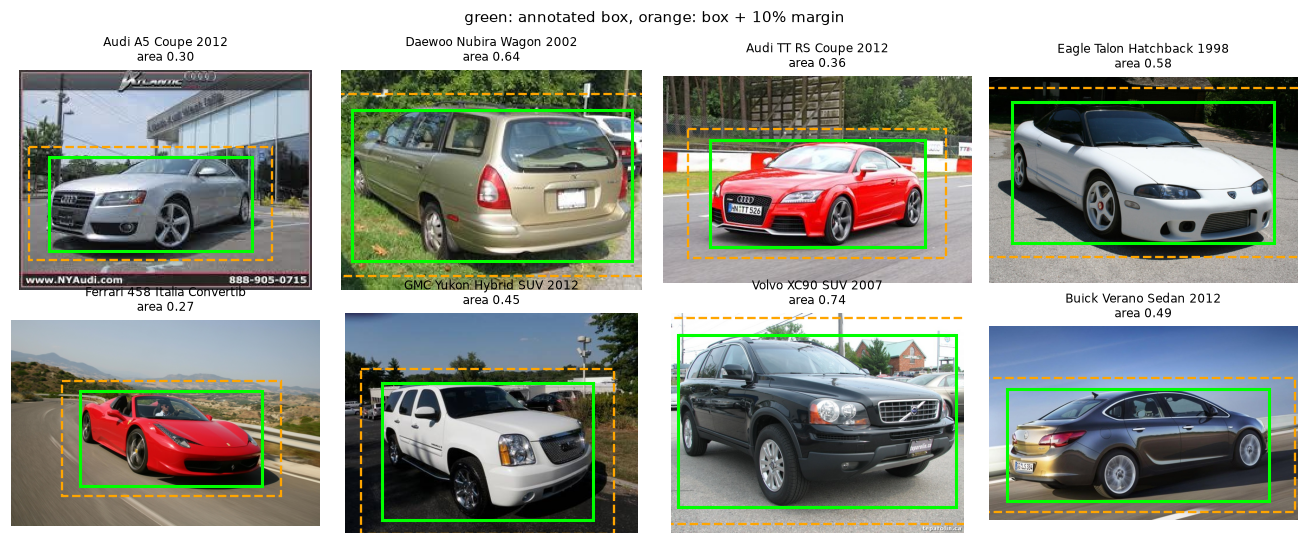

In [8]:
def show_boxes(rows, margin=C.BBOX_MARGIN):
    fig, axes = plt.subplots(2, 4, figsize=(12, 5))
    for ax, (_, r) in zip(axes.ravel(), rows.iterrows()):
        img = Image.open(C.IMAGE_ROOT / r.path).convert("RGB")
        ax.imshow(img)
        ax.add_patch(plt.Rectangle((r.x1, r.y1), r.bw, r.bh, fill=False, ec="lime", lw=2))
        mx, my = margin * r.bw, margin * r.bh
        ax.add_patch(plt.Rectangle((r.x1 - mx, r.y1 - my), r.bw + 2 * mx, r.bh + 2 * my,
                                   fill=False, ec="orange", lw=1.5, ls="--"))
        ax.set_title(f"{r.class_name[:28]}\narea {r.area_ratio:.2f}", fontsize=8)
        ax.axis("off")
    fig.suptitle(f"green: annotated box, orange: box + {margin:.0%} margin", fontsize=10)
    fig.tight_layout()
    return fig

sample = df.sample(8, random_state=C.SEED)
show_boxes(sample).savefig(FIG_DIR / "eda_bbox_overlay.png")

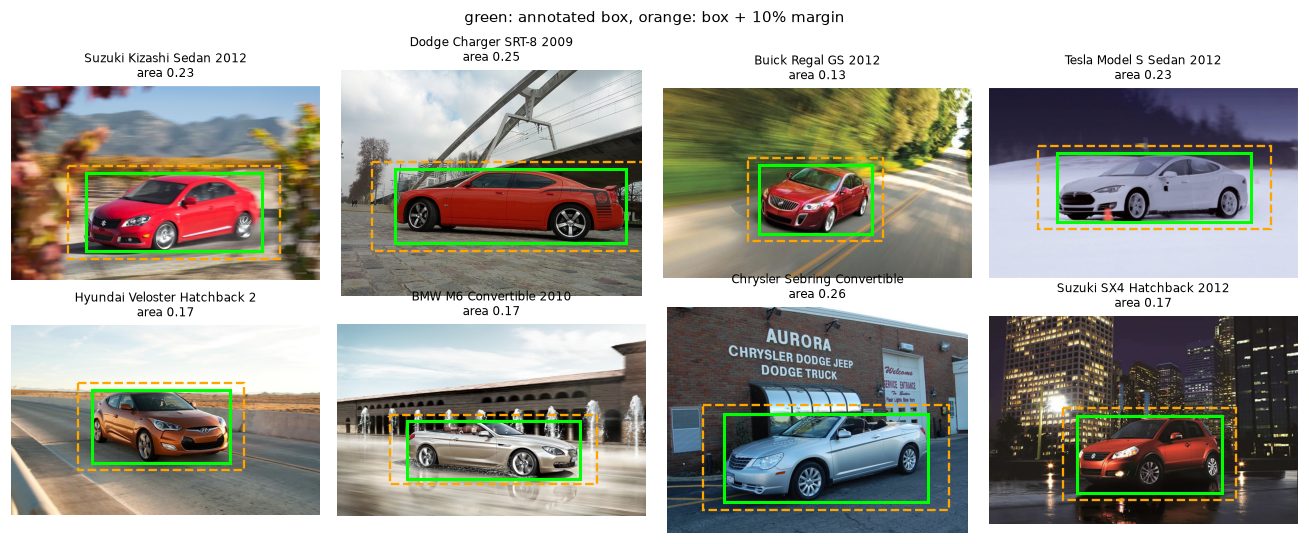

In [9]:
tight = df.nsmallest(400, "area_ratio").sample(8, random_state=C.SEED)
show_boxes(tight);

**What we learn:** boxes are tight around the car, often touching mirrors and bumpers. Images with a small
area ratio are mostly wide scenes where the car is far away, which is closer to what a street camera sees.

**Impact on next steps:** a tight crop can clip mirrors or bumper corners, so we add a 10% margin on each
side (orange). It keeps the full silhouette, tolerates small box errors (which a real detector like YOLO will
make later), and still removes most of the background.

## 8. Classes that are easy to confuse within one make

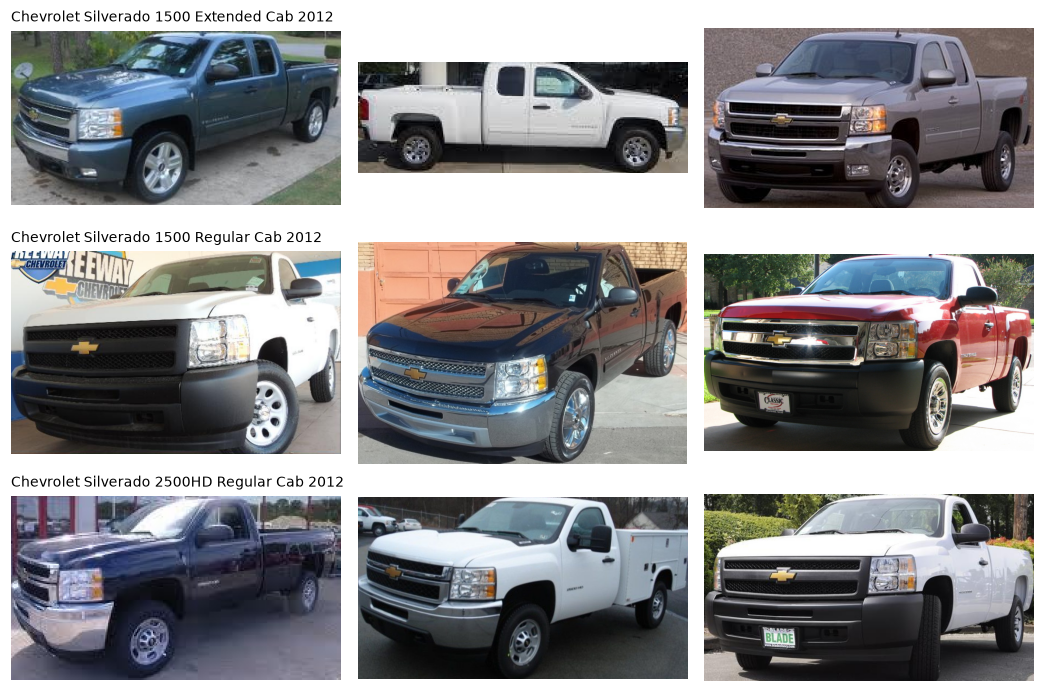

In [10]:
def side_by_side(class_names, n=3):
    fig, axes = plt.subplots(len(class_names), n, figsize=(3.2 * n, 2.2 * len(class_names)))
    for row, name in zip(axes, class_names):
        for ax, (_, r) in zip(row, df[df.class_name == name].sample(n, random_state=C.SEED).iterrows()):
            img = Image.open(C.IMAGE_ROOT / r.path).convert("RGB").crop((r.x1, r.y1, r.x2, r.y2))
            ax.imshow(img); ax.axis("off")
        row[0].set_title(name, fontsize=9, loc="left")
    fig.tight_layout()
    return fig

side_by_side(["Chevrolet Silverado 1500 Extended Cab 2012", "Chevrolet Silverado 1500 Regular Cab 2012",
              "Chevrolet Silverado 2500HD Regular Cab 2012"]).savefig(FIG_DIR / "eda_confusable_silverado.png")

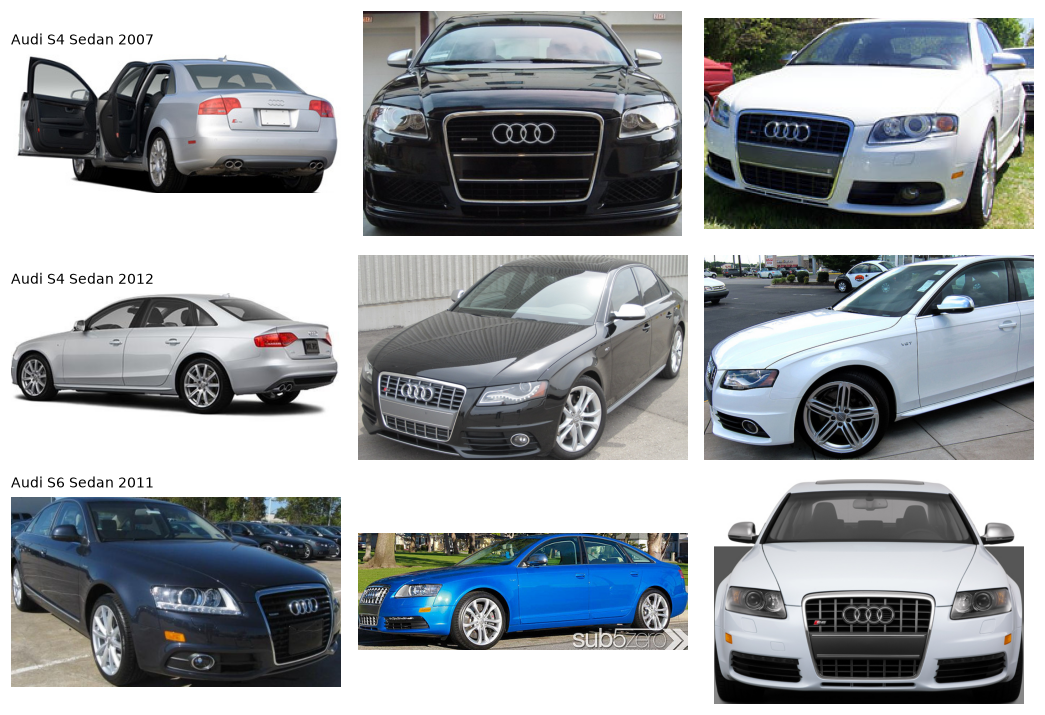

In [11]:
side_by_side(["Audi S4 Sedan 2007", "Audi S4 Sedan 2012", "Audi S6 Sedan 2011"]);

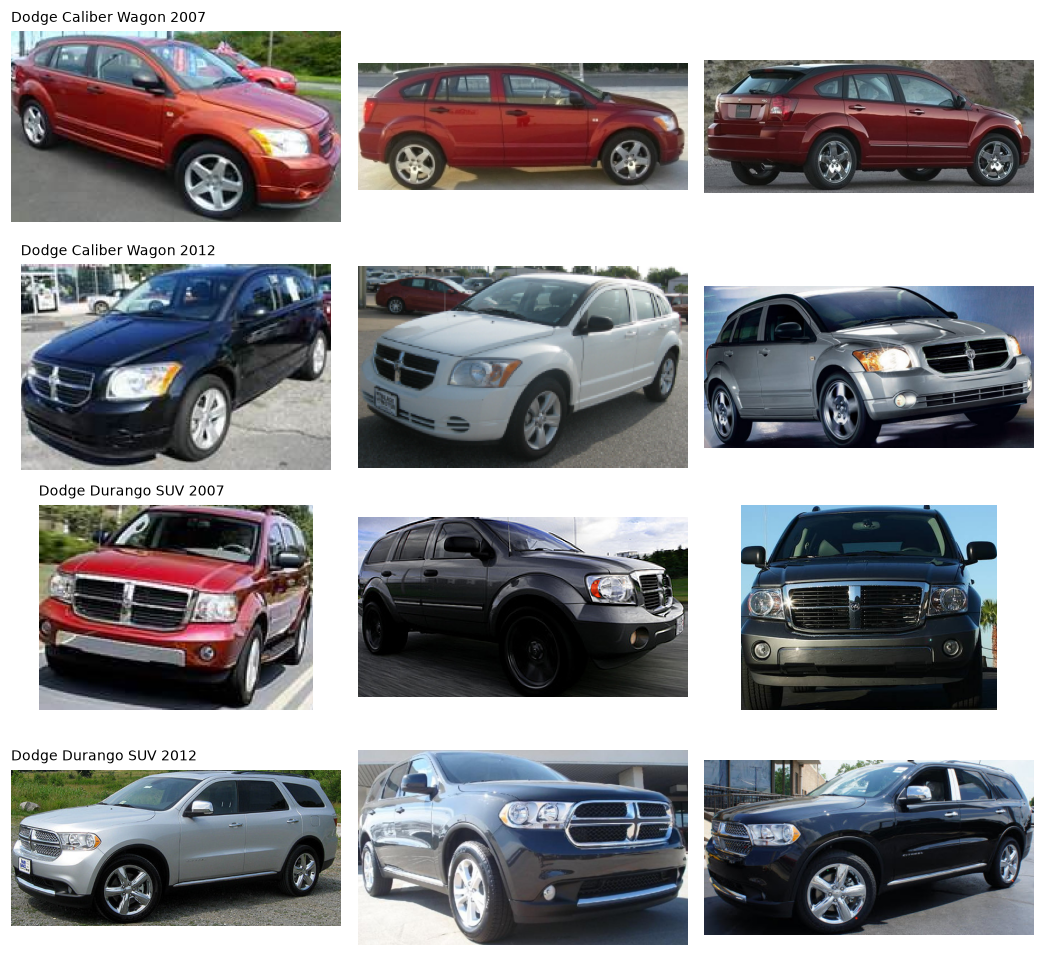

In [12]:
side_by_side(["Dodge Caliber Wagon 2007", "Dodge Caliber Wagon 2012", "Dodge Durango SUV 2007", "Dodge Durango SUV 2012"]);

**What we learn:** some pairs differ only in cab length, a trim badge, or a facelift (headlight shape,
grille). Viewpoint and color change far more between images of the same class than these details change
between classes. This is what "fine-grained" means: high within-class variation, low between-class variation.

**Impact on next steps:** we keep horizontal flip (a mirrored car is still the same model) but do not use
vertical flip (upside-down cars do not exist). Random crops stay mild (at least 50% of the area) so the
detail that separates two classes is not cropped away. Hue jitter is off because color is not a label cue
but strong hue shifts make unrealistic images. We expect the hardest confusions to be pairs like these.

## Summary

| Finding | Decision |
|---|---|
| 20 to 58 images per class, mild imbalance | no class weights, ImageNet pretraining, early stopping |
| big makes hold most classes | report within-make vs cross-make errors |
| most models are 2012 or older | confidence threshold for unknown models |
| cars are about 1.9:1 wide | resize to 224 x 224 directly, no center crop |
| car covers about half the image | compare full image vs bbox crop |
| tight boxes | 10% margin around the crop |
| differences are small details | mild random crop, hflip only, no hue jitter |